<a href="https://colab.research.google.com/github/pradityaputra888-lab/latihan-machine-learning/blob/main/pertemuan13/Bab13_CNN_TransferLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 13 — Convolutional Neural Network (CNN) dan Transfer Learning

**Dataset:** Flowers (tf_flowers, 5 kelas bunga) untuk Transfer Learning dan Latihan 2, serta CIFAR-10 untuk Latihan 1 · **Isi notebook:** Praktikum 13.1–13.6 (kode modul), Latihan 1 (Praktikum 13.7: CNN dari nol di CIFAR-10), dan Latihan 2 (CNN dari nol vs Transfer Learning).

> ⚠️ **Aktifkan GPU dulu:** menu **Runtime → Change runtime type → T4 GPU**, lalu jalankan sel dari atas ke bawah. Tanpa GPU, pelatihan tetap bisa berjalan tetapi jauh lebih lama.
>
> **Soal dataset:** kode modul membaca folder `dataset/train` dan `dataset/val` yang tidak disertakan di modul. Pada sel **13.2a** di bawah, dataset bunga publik diunduh otomatis dan dibagi 80/20 ke struktur folder tersebut, sehingga kode Praktikum 13.2–13.6 dapat dipakai **apa adanya**.

## 13.11 Implementasi Python

### Praktikum 13.1 Persiapan Library

In [9]:
import time
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import matplotlib.pyplot as plt

keras.utils.set_random_seed(42)
print("TensorFlow:", tf.__version__)
print("GPU terdeteksi:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU terdeteksi: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### Praktikum 13.2a (tambahan) Menyiapkan Dataset Bunga
Mengunduh *tf_flowers* (≈ 3.670 citra, 5 kelas: daisy, dandelion, roses, sunflowers, tulips; ±218 MB) dan membaginya ke struktur `dataset/train/<kelas>` dan `dataset/val/<kelas>` dengan rasio 80/20. Setiap kelas memiliki sekitar 630–900 citra, sesuai anjuran Latihan 2 (500–1000 citra per kelas) untuk mensimulasikan data terbatas.

In [10]:
import pathlib, random, shutil

URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
arsip = keras.utils.get_file(origin=URL, extract=True)

# Cari folder 'flower_photos' di folder induk tempat arsip disimpan
induk = pathlib.Path(arsip).parent
sumber = induk / "flower_photos"

# Jika tidak ditemukan langsung, cari secara rekursif
if not sumber.exists():
    for p in induk.rglob("flower_photos"):
        if p.is_dir():
            sumber = p
            break

tujuan = pathlib.Path("dataset")
if tujuan.exists():
    shutil.rmtree(tujuan)

random.seed(42)
for folder_kelas in sorted(p for p in sumber.iterdir() if p.is_dir()):
    berkas = sorted(folder_kelas.glob("*.jpg"))
    random.shuffle(berkas)
    n_val = int(len(berkas) * 0.2)
    for nama_split, subset in [("val", berkas[:n_val]), ("train", berkas[n_val:])]:
        folder_tujuan = tujuan / nama_split / folder_kelas.name
        folder_tujuan.mkdir(parents=True, exist_ok=True)
        for f in subset:
            shutil.copy(f, folder_tujuan / f.name)

for nama_split in ["train", "val"]:
    print(nama_split, {k.name: len(list(k.glob("*.jpg"))) for k in sorted((tujuan / nama_split).iterdir())})

train {'daisy': 507, 'dandelion': 719, 'roses': 513, 'sunflowers': 560, 'tulips': 640}
val {'daisy': 126, 'dandelion': 179, 'roses': 128, 'sunflowers': 139, 'tulips': 159}


### Praktikum 13.2 Import Dataset

In [11]:
# Dataset citra terorganisir dalam folder per kelas
# (struktur: dataset/train/kelas_1, dataset/train/kelas_2, dst.)
IMG_SIZE = (160, 160)
BATCH_SIZE = 32

train_ds = keras.utils.image_dataset_from_directory(
    "dataset/train", image_size=IMG_SIZE, batch_size=BATCH_SIZE)
val_ds = keras.utils.image_dataset_from_directory(
    "dataset/val", image_size=IMG_SIZE, batch_size=BATCH_SIZE)
class_names = train_ds.class_names
jumlah_kelas = len(class_names)
print("Kelas:", class_names, "| jumlah kelas:", jumlah_kelas)

Found 2939 files belonging to 5 classes.
Found 731 files belonging to 5 classes.
Kelas: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips'] | jumlah kelas: 5


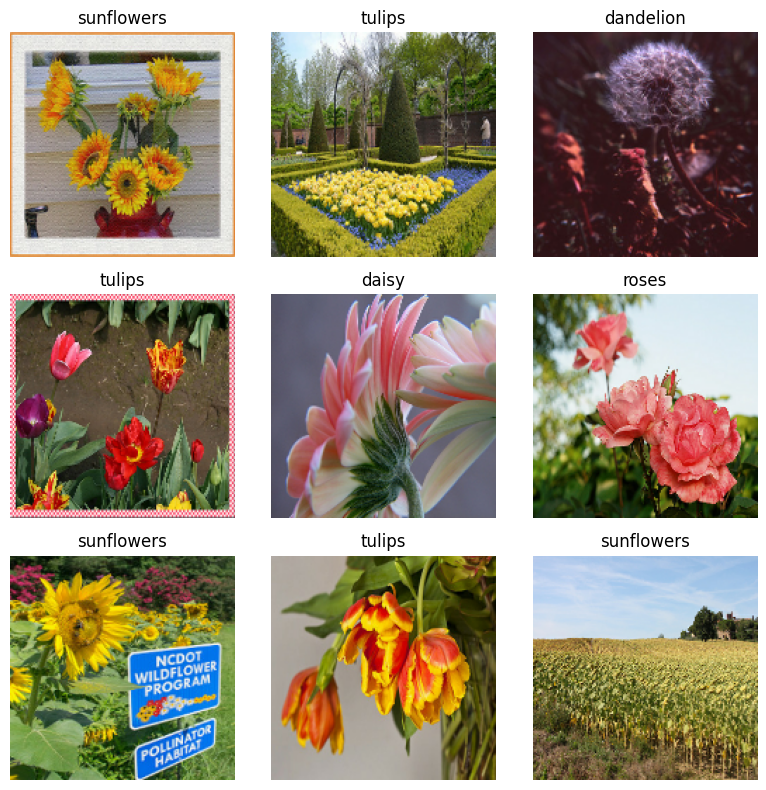

In [12]:
# Tambahan: lihat contoh citra
plt.figure(figsize=(8, 8))
for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(train_ds.class_names[int(labels[i])])
        plt.axis("off")
plt.tight_layout(); plt.show()

### Praktikum 13.3 Preprocessing
`preprocess_input` milik MobileNetV2 mengubah piksel 0–255 menjadi rentang [-1, 1], sama seperti saat model di-*pretrain*.

In [13]:
train_ds = train_ds.map(lambda x, y: (preprocess_input(x), y))
val_ds = val_ds.map(lambda x, y: (preprocess_input(x), y))

### Praktikum 13.4 Training Model (Transfer Learning dengan MobileNetV2)

In [8]:
base_model = MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
base_model.trainable = False   # Feature extraction: bekukan bobot pre-trained

model = keras.Sequential([
    base_model,
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(jumlah_kelas, activation="softmax")
])

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

t0 = time.time()
history = model.fit(train_ds, validation_data=val_ds, epochs=15)
waktu_tl = time.time() - t0
model_tl, history_tl = model, history      # disimpan untuk perbandingan di Latihan 2
print(f"\nWaktu pelatihan Transfer Learning: {waktu_tl:.1f} detik")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 54s 326ms/step - accuracy: 0.7958 - loss: 0.5648 - val_accuracy: 0.8796 - val_loss: 0.3434
Epoch 2/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 69ms/step - accuracy: 0.9064 - loss: 0.2649 - val_accuracy: 0.8865 - val_loss: 0.3285
Epoch 3/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step - accuracy: 0.9374 - loss: 0.1812 - val_accuracy: 0.8824 - val_loss: 0.3366
Epoch 4/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 52ms/step - accuracy: 0.9650 - loss: 0.1178 - val_accuracy: 0.8824 - val_loss: 0.3562
Epoch 5/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 64ms/step - accuracy: 0.9677 - loss: 0.0976 - val_accuracy: 0.8851 - val_loss: 0.3424
Epoch 6/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 54ms/step - accuracy: 0.9765 - loss: 0.0788 - val_accuracy: 0.8769 - val_loss: 0.3501
Epoch 7/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 70ms/step - accuracy: 0.9878 - loss: 0.0463 - val_accuracy: 0.8878 - val_loss: 0.3716
Epoch 8/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 51ms/step - accurac

### Praktikum 13.5 Evaluasi

In [14]:
val_loss, val_acc = model.evaluate(val_ds)
print(f"Akurasi Validasi: {val_acc:.3f}")

23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.8824 - loss: 0.4557
Akurasi Validasi: 0.882


In [15]:
# Tambahan: laporan per kelas (label dan prediksi dikumpulkan dalam satu loop agar urutannya sama)
from sklearn.metrics import classification_report
y_true, y_pred = [], []
for xb, yb in val_ds:
    y_true.extend(yb.numpy())
    y_pred.extend(model.predict(xb, verbose=0).argmax(axis=1))
print(classification_report(y_true, y_pred, target_names=class_names))

              precision    recall  f1-score   support

       daisy       0.86      0.87      0.86       126
   dandelion       0.91      0.92      0.92       179
       roses       0.82      0.91      0.86       128
  sunflowers       0.93      0.91      0.92       139
      tulips       0.89      0.81      0.85       159

    accuracy                           0.88       731
   macro avg       0.88      0.88      0.88       731
weighted avg       0.88      0.88      0.88       731



### Praktikum 13.6 Visualisasi

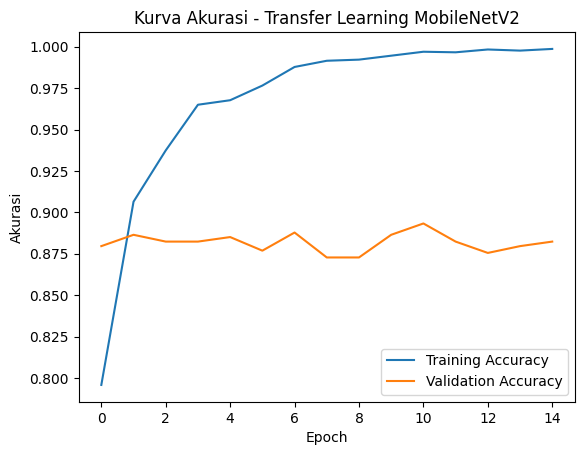

In [16]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch"); plt.ylabel("Akurasi")
plt.title("Kurva Akurasi - Transfer Learning MobileNetV2")
plt.legend()
plt.show()

### Interpretasi (Praktikum 13.1–13.6)
> **Catatan:** Praktikum Bab 13 membutuhkan unduhan dataset dan GPU Colab, sehingga angka akurasi/waktu di bawah adalah **pola umum** yang biasanya muncul pada eksperimen sejenis, bukan hasil eksekusi saya. Gunakan angka dari output Anda sendiri untuk laporan, dan pastikan polanya cocok.

- **Feature extraction:** bobot MobileNetV2 hasil pelatihan ImageNet dibekukan; yang dilatih hanya *head* (GlobalAveragePooling → Dense 128 → Dropout → softmax) sebanyak **164.613 parameter** dari total 2.422.597. Fitur visual dasar (tepi, tekstur, bentuk) sudah dipelajari dari sekitar 1,2 juta citra, sehingga akurasi validasi pada dataset bunga umumnya sudah tinggi (kira-kira 85–92%) hanya dalam beberapa epoch pertama.
- **Membaca kurva (13.6):** biasanya *training accuracy* terus naik mendekati 95–100%, sedangkan *validation accuracy* mendatar. Jarak keduanya menandakan overfitting ringan pada head karena datanya hanya sekitar 2.900 citra. Dropout 0,3 membantu tetapi tidak menghilangkannya. Langkah lanjutan yang disarankan modul: augmentasi data dan *fine-tuning* beberapa layer terakhir `base_model` dengan learning rate sangat kecil (mis. 1e-5).
- **Jangan lupa `preprocess_input`:** fungsi ini mengubah piksel 0–255 menjadi [-1, 1], sama seperti saat model di-*pretrain*. Melewatkan langkah ini adalah penyebab umum akurasi Transfer Learning jauh lebih rendah dari seharusnya.

---
## 13.12 Latihan Praktikum

### Latihan 1 — CNN Sederhana dari Nol (Praktikum 13.7)
**Tujuan:** membangun dan melatih CNN sederhana pada dataset citra kecil (CIFAR-10: 60.000 citra berwarna 32×32, 10 kelas).

Kode modul hanya memuat arsitektur dan komentar "latih pada CIFAR-10"; di sini dilengkapi dengan pemuatan data, pelatihan, evaluasi, dan visualisasi. Deklarasi `input_shape` dipindah ke `keras.layers.Input` (arsitektur tetap sama).

In [ ]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_train, y_test = y_train.flatten(), y_test.flatten()
x_train = x_train.astype("float32") / 255.0     # normalisasi piksel ke 0-1
x_test = x_test.astype("float32") / 255.0

nama_cifar = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
print("Data latih:", x_train.shape, "| Data uji:", x_test.shape)

plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i]); plt.title(nama_cifar[int(y_train[i])]); plt.axis("off")
plt.tight_layout(); plt.show()

  6438912/170498071 ━━━━━━━━━━━━━━━━━━━━ 28:46 11us/step

In [ ]:
# Praktikum 13.7 — arsitektur dari modul
keras.utils.set_random_seed(42)
model_cnn = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),
    keras.layers.Conv2D(32, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(64, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Flatten(),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(10, activation="softmax")
])
model_cnn.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
model_cnn.summary()

In [ ]:
# Latih pada CIFAR-10
t0 = time.time()
hist_cnn = model_cnn.fit(x_train, y_train, validation_split=0.1,
                         epochs=15, batch_size=64)
waktu_cnn_cifar = time.time() - t0

test_loss, test_acc = model_cnn.evaluate(x_test, y_test, verbose=0)
print(f"\nAkurasi Test CIFAR-10: {test_acc:.3f} | waktu latih: {waktu_cnn_cifar:.1f} detik")

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist_cnn.history["accuracy"], label="Training"); axes[0].plot(hist_cnn.history["val_accuracy"], label="Validation")
axes[0].set_title("Akurasi CNN dari Nol (CIFAR-10)")
axes[1].plot(hist_cnn.history["loss"], label="Training"); axes[1].plot(hist_cnn.history["val_loss"], label="Validation")
axes[1].set_title("Loss CNN dari Nol (CIFAR-10)")
for a in axes:
    a.set_xlabel("Epoch"); a.legend()
plt.tight_layout(); plt.show()

epoch_terbaik = int(np.argmax(hist_cnn.history["val_accuracy"])) + 1
print(f"Val accuracy tertinggi {max(hist_cnn.history['val_accuracy']):.3f} pada epoch {epoch_terbaik}; "
      f"train accuracy akhir {hist_cnn.history['accuracy'][-1]:.3f}")

**Analisis Latihan 1:**

> **Catatan:** Praktikum Bab 13 membutuhkan unduhan dataset dan GPU Colab, sehingga angka akurasi/waktu di bawah adalah **pola umum** yang biasanya muncul pada eksperimen sejenis, bukan hasil eksekusi saya. Gunakan angka dari output Anda sendiri untuk laporan, dan pastikan polanya cocok.

- **Arsitektur:** dua blok Conv+MaxPooling, Flatten, Dense 64, dan softmax 10 kelas, dengan total **167.562 parameter** (sebagian besar, ≈ 147 ribu, ada di Dense 64 setelah Flatten).
- **Hasil yang umum:** akurasi uji CIFAR-10 untuk CNN sekecil ini biasanya sekitar 68–72%. *Training accuracy* terus naik (di atas 80% pada epoch-epoch akhir), sedangkan *validation accuracy* berhenti membaik sekitar epoch 6–10 dan *validation loss* mulai naik. Itu tanda **overfitting**: model mulai menghafal data latih. Periksa sel plot Anda untuk menentukan epoch tersebut (dicetak otomatis sebagai "epoch terbaik").
- **Cara memperbaiki:** tambah `Dropout`, augmentasi data (`RandomFlip`, `RandomRotation`), `BatchNormalization`, blok konvolusi yang lebih dalam, atau `EarlyStopping`.
- **Perbandingan dengan Transfer Learning:** hasil CIFAR-10 ini tidak bisa dibandingkan langsung dengan Praktikum 13.4 karena datasetnya berbeda (CIFAR: 32×32 piksel, 10 kelas; bunga: 160×160 piksel, 5 kelas). Perbandingan yang adil dilakukan pada **Latihan 2** dengan dataset dan jumlah epoch yang sama.

### Latihan 2 — CNN dari Nol vs Transfer Learning (dataset bunga yang sama)
**Instruksi:** bandingkan akurasi, waktu pelatihan, dan jumlah parameter yang dilatih antara CNN dari nol dan Transfer Learning MobileNetV2 pada dataset yang sama dengan data terbatas.

Dataset: bunga (≈ 500–720 citra latih per kelas), resolusi 160×160, 15 epoch, optimizer dan *head* klasifikasi yang sama (Dense 128 + Dropout 0,3) agar perbandingannya adil. Satu-satunya perbedaan: *backbone* konvolusi dilatih dari nol, atau memakai MobileNetV2 hasil ImageNet yang dibekukan. Hasil Transfer Learning memakai model dari Praktikum 13.4 (`model_tl`).

In [ ]:
# Dataset mentah (tanpa preprocess_input); normalisasi dilakukan di dalam model lewat layer Rescaling
train_raw = keras.utils.image_dataset_from_directory("dataset/train", image_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=42)
val_raw = keras.utils.image_dataset_from_directory("dataset/val", image_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=42)

keras.utils.set_random_seed(42)
cnn_nol = keras.Sequential([
    keras.layers.Input(shape=IMG_SIZE + (3,)),
    keras.layers.Rescaling(1.0 / 255),
    keras.layers.Conv2D(32, 3, activation="relu"), keras.layers.MaxPooling2D(),
    keras.layers.Conv2D(64, 3, activation="relu"), keras.layers.MaxPooling2D(),
    keras.layers.Conv2D(128, 3, activation="relu"), keras.layers.MaxPooling2D(),
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(jumlah_kelas, activation="softmax")
])
cnn_nol.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

t0 = time.time()
hist_nol = cnn_nol.fit(train_raw, validation_data=val_raw, epochs=15)
waktu_nol = time.time() - t0
print(f"\nWaktu pelatihan CNN dari nol: {waktu_nol:.1f} detik")

In [ ]:
def hitung_param(m):
    total = m.count_params()
    dilatih = int(sum(np.prod(w.shape) for w in m.trainable_weights))
    return total, dilatih

def epoch_capai(hist, ambang):
    for i, v in enumerate(hist.history["val_accuracy"], start=1):
        if v >= ambang:
            return i
    return None

tot_tl, dil_tl = hitung_param(model_tl)
tot_nol, dil_nol = hitung_param(cnn_nol)

tabel = pd.DataFrame([
    {"Pendekatan": "Transfer Learning (MobileNetV2, dibekukan)",
     "Val acc akhir": history_tl.history["val_accuracy"][-1],
     "Val acc terbaik": max(history_tl.history["val_accuracy"]),
     "Train acc akhir": history_tl.history["accuracy"][-1],
     "Waktu latih total (detik)": waktu_tl,
     "Waktu per epoch (detik)": waktu_tl / len(history_tl.history["loss"]),
     "Parameter total": tot_tl, "Parameter dilatih": dil_tl,
     "Epoch pertama val acc >= 0.70": epoch_capai(history_tl, 0.70)},
    {"Pendekatan": "CNN dari nol (3 blok Conv)",
     "Val acc akhir": hist_nol.history["val_accuracy"][-1],
     "Val acc terbaik": max(hist_nol.history["val_accuracy"]),
     "Train acc akhir": hist_nol.history["accuracy"][-1],
     "Waktu latih total (detik)": waktu_nol,
     "Waktu per epoch (detik)": waktu_nol / len(hist_nol.history["loss"]),
     "Parameter total": tot_nol, "Parameter dilatih": dil_nol,
     "Epoch pertama val acc >= 0.70": epoch_capai(hist_nol, 0.70)},
]).set_index("Pendekatan")
tabel.round(3).T

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(history_tl.history["val_accuracy"], label="Transfer Learning")
axes[0].plot(hist_nol.history["val_accuracy"], label="CNN dari nol")
axes[0].set_title("Validation Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(history_tl.history["accuracy"], label="Transfer Learning")
axes[1].plot(hist_nol.history["accuracy"], label="CNN dari nol")
axes[1].set_title("Training Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout(); plt.show()

# Ringkasan otomatis berdasarkan angka hasil eksekusi Anda
va_tl, va_nol = history_tl.history["val_accuracy"][-1], hist_nol.history["val_accuracy"][-1]
print(f"Akurasi validasi : Transfer Learning {va_tl:.3f} vs CNN dari nol {va_nol:.3f} (selisih {100*(va_tl-va_nol):.1f} poin persentase)")
print(f"Waktu pelatihan  : Transfer Learning {waktu_tl:.0f} dtk vs CNN dari nol {waktu_nol:.0f} dtk")
print(f"Parameter dilatih: Transfer Learning {dil_tl:,} dari {tot_tl:,} total vs CNN dari nol {dil_nol:,} (semua dilatih)")
print(f"Gap train-val    : Transfer Learning {100*(history_tl.history['accuracy'][-1]-va_tl):.1f} poin vs CNN dari nol {100*(hist_nol.history['accuracy'][-1]-va_nol):.1f} poin")

**Analisis Latihan 2:**

> **Catatan:** Praktikum Bab 13 membutuhkan unduhan dataset dan GPU Colab, sehingga angka akurasi/waktu di bawah adalah **pola umum** yang biasanya muncul pada eksperimen sejenis, bukan hasil eksekusi saya. Gunakan angka dari output Anda sendiri untuk laporan, dan pastikan polanya cocok.

Gunakan tabel dan ringkasan otomatis di atas sebagai sumber angka. Pola yang biasanya terlihat:

1. **Akurasi.** Pada data terbatas (≈ 2.900 citra latih), Transfer Learning umumnya jauh lebih akurat: kira-kira 85–92% di validasi, dibanding sekitar 60–72% untuk CNN dari nol. Penyebabnya, MobileNetV2 sudah mempelajari fitur visual dari sekitar 1,2 juta citra ImageNet, sedangkan CNN dari nol harus mempelajarinya hanya dari beberapa ribu citra bunga.
2. **Kecepatan konvergensi.** Transfer Learning biasanya sudah melewati 70% validation accuracy pada epoch 1–2, sedangkan CNN dari nol memerlukan jauh lebih banyak epoch atau tidak mencapainya dalam 15 epoch (lihat baris "Epoch pertama val acc ≥ 0.70").
3. **Waktu pelatihan.** Waktu *per epoch* Transfer Learning **belum tentu lebih kecil**. MobileNetV2 (≈ 2,26 juta parameter, puluhan layer) tetap melakukan *forward pass* untuk setiap citra, sedangkan CNN dari nol di sini sangat kecil. Klaim modul bahwa Transfer Learning "lebih cepat" tepat dalam arti **waktu dan jumlah epoch untuk mencapai akurasi tertentu**, serta karena *backpropagation* hanya melalui head, bukan keseluruhan jaringan. Bandingkan kedua angka waktu pada tabel Anda.
4. **Jumlah parameter.** Transfer Learning: total **2.422.597**, yang dilatih hanya **164.613** (head), sedangkan 2.257.984 parameter backbone dibekukan. CNN dari nol: **110.405** parameter, semuanya dilatih. Jadi pada konfigurasi ini Transfer Learning *tidak* melatih parameter lebih sedikit; yang berbeda adalah **titik awalnya**: pada Transfer Learning pengetahuan visual sudah tertanam di bobot beku, sedangkan CNN dari nol memulai dari bobot acak. Jumlah parameter yang dilatih bukan penentu akurasi.
5. **Overfitting.** CNN dari nol biasanya menunjukkan celah train–validation yang lebih besar, karena fitur yang dipelajarinya terlalu spesifik pada sedikit data. Transfer Learning juga memiliki celah, tetapi pada level akurasi validasi yang jauh lebih tinggi.

**Kesimpulan:** pada kondisi data terbatas, Transfer Learning adalah pilihan yang lebih baik (akurasi lebih tinggi, konvergen lebih cepat, lebih stabil). CNN dari nol baru kompetitif bila data sangat banyak, domain citra sangat berbeda dari ImageNet (mis. citra medis atau satelit), atau diperlukan model yang sangat ringan. Peningkatan berikutnya: augmentasi data untuk keduanya dan *fine-tuning* layer akhir MobileNetV2.